# TLS transition-time resolution stability

This notebook checks whether the inferred TLS and TLS$^{\mathrm{CL}}$ parameters change appreciably between transition-time discretizations. It reads the saved fit outputs directly; it does not rerun inference or modify the input files.

The primary comparison is $N=75$ versus $N=100$. A secondary $N=100$ versus $N=200$ comparison is included for TLS$^{\mathrm{CL}}$ when the saved schedule contains 200 transition times. The 3% threshold below is a practical, **post hoc** stability criterion, not a threshold specified by the fitting workflow.

Transition states are indexed as 0=NMP, 1=S, and 2=NT. Rates are calculated in the original branch-length units; branch lengths are not rescaled here.

In [1]:
from pathlib import Path
import math
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

repo_root = next(
(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data/troupe/TLS/fixed_sampling_0.1").is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Could not locate the repository data/troupe directory from the current working directory.")

RUN_FILES = {
    ("TLS", 75): ("data/troupe/TLS/fixed_sampling_0.1/inference_transition_times_75.tmp.out", "checkpoint"),
    ("TLS", 100): ("data/troupe/TLS/fixed_sampling_0.1/inference_transition_times_100.tmp.out", "checkpoint"),
    ("TLS", 200): ("data/troupe/TLS/fixed_sampling_0.1/inference_transition_times_200.tmp.out", "checkpoint"),
    ("TLSC", 75): ("data/troupe/TLSC/fixed_sampling_0.1/inference_transition_times_75.out", "completed output"),
    ("TLSC", 100): ("data/troupe/TLSC/fixed_sampling_0.1/inference_transition_times_100.out", "completed output"),
    ("TLSC", 200): ("data/troupe/TLSC/fixed_sampling_0.1/inference_transition_times_200.tmp.out", "checkpoint"),
}

RELATIVE_CHANGE_LIMIT_PERCENT = 3.0
NEAR_ZERO_ABSOLUTE_THRESHOLD = 1e-6


In [2]:
def read_fit(condition, requested_n, relative_path, artifact_status):
    """Read one text fit output and derive the reported stability metrics."""
    path = repo_root / relative_path
    if not path.is_file():
        raise FileNotFoundError(f"Missing fit output: {path}")
    text = path.read_text()

    def read_vector(name):
        match = re.search(rf"^{re.escape(name)}:\s*(.*)$", text, re.MULTILINE)
        if match is None:
            raise ValueError(f"Missing '{name}:' line in {path}")
        return [float(value) for value in match.group(1).split()]

    birth = read_vector("birth")
    death = read_vector("death")
    sampling = read_vector("sampling")
    if not (len(birth) == len(death) == len(sampling) == 3):
        raise ValueError(f"Expected three state values (NMP, S, NT) in {path}")

    transition_match = re.search(r"^transitions:\s*$", text, re.MULTILINE)
    times_match = re.search(r"^transition_times:\s*$", text, re.MULTILINE)
    if transition_match is None or times_match is None:
        raise ValueError(f"Missing transitions or transition_times section in {path}")

    transitions = {
        (int(source), int(destination)): float(probability)
        for source, destination, probability in re.findall(
            r"^(\d+)->(\d+)\s+([0-9.eE+-]+)$", text, re.MULTILINE
        )
    }
    times_text = text[times_match.end():]
    indexed_times = [
        (int(index), float(time))
        for index, time in re.findall(r"^(\d+)\s+([0-9.eE+-]+)$", times_text, re.MULTILINE)
    ]
    actual_n = len(indexed_times)
    if actual_n == 0:
        raise ValueError(f"No transition times found in {path}")
    if (0, 1) not in transitions or (0, 2) not in transitions:
        raise ValueError(f"Missing NMP-to-S or NMP-to-NT transition probability in {path}")

    # The first recorded time is 0.0001; subsequent indexed times follow i/N.
    schedule_matches_actual_n = all(
        index == expected_index
        and (index == 0 or math.isclose(time, index / actual_n, rel_tol=1e-7, abs_tol=1e-8))
        for expected_index, (index, time) in enumerate(indexed_times)
    )
    delta_t = 1 / actual_n
    relative_rates = {
        "a_NMP": birth[0] - death[0],
        "a_S": birth[1] - death[1],
        "a_NT": birth[2] - death[2],
        "b_NMP": birth[0] * sampling[0],
        "b_S": birth[1] * sampling[1],
        "b_NT": birth[2] * sampling[2],
        "q_NMP_to_S": transitions[(0, 1)] / delta_t,
        "q_NMP_to_NT": transitions[(0, 2)] / delta_t,
        "ratio_S_over_NT": transitions[(0, 1)] / transitions[(0, 2)],
    }

    stderr_path = path.parent / f"inference_transition_times_{requested_n}.stderr.log"
    stderr_contains_traceback = (
        stderr_path.is_file()
        and "Traceback" in stderr_path.read_text(errors="replace")
    )

    return {
        "condition": condition,
        "requested_N": requested_n,
        "actual_N": actual_n,
        "artifact_status": artifact_status,
        "schedule_matches_actual_N": schedule_matches_actual_n,
        "resolution_matches_request": actual_n == requested_n,
        "stderr_contains_traceback": stderr_contains_traceback,
        "relative_path": relative_path,
        **relative_rates,
    }


fits = {}
for (condition, requested_n), (relative_path, artifact_status) in RUN_FILES.items():
    fits[(condition, requested_n)] = read_fit(condition, requested_n, relative_path, artifact_status)

audit = pd.DataFrame(fits.values())
display(audit[[
    "condition", "requested_N", "actual_N", "artifact_status",
    "schedule_matches_actual_N", "resolution_matches_request",
    "stderr_contains_traceback", "relative_path",
]])


,condition,requested_N,actual_N,artifact_status,schedule_matches_actual_N,resolution_matches_request,stderr_contains_traceback,relative_path
0,TLS,75,75,checkpoint,True,True,False,data/troupe/TLS/fixed_sampling_0.1/inference_t...
1,TLS,100,100,checkpoint,True,True,False,data/troupe/TLS/fixed_sampling_0.1/inference_t...
2,TLS,200,100,checkpoint,True,False,True,data/troupe/TLS/fixed_sampling_0.1/inference_t...
3,TLSC,75,75,completed output,True,True,False,data/troupe/TLSC/fixed_sampling_0.1/inference_...
4,TLSC,100,100,completed output,True,True,False,data/troupe/TLSC/fixed_sampling_0.1/inference_...
5,TLSC,200,200,checkpoint,True,True,False,data/troupe/TLSC/fixed_sampling_0.1/inference_...


## Criterion and comparison

For each non-negligible estimate $x$, compute the symmetric relative difference

$$100\,\frac{|x_{N_2}-x_{N_1}|}{\max(|x_{N_1}|,|x_{N_2}|)}.$$

The pair passes if every non-negligible metric changes by at most 3%. Estimates for which both magnitudes are below $10^{-6}$ in the original rate units are treated as near zero: their absolute difference is reported and they are not assigned a misleading relative percentage. The notebook also reports the conventional percentage relative to the lower-resolution estimate so that the normalization is explicit.

The primary comparisons are TLS 75-to-100 and TLS$^{\mathrm{CL}}$ 75-to-100. TLS$^{\mathrm{CL}}$ 100-to-200 is a secondary check; its $N=200$ fit is a checkpoint, not a finalized output.

In [3]:
METRICS = [
    "a_NMP", "a_S", "a_NT",
    "b_NMP", "b_S", "b_NT",
    "q_NMP_to_S", "q_NMP_to_NT", "ratio_S_over_NT",
]
COMPARISONS = [
    ("TLS", 75, 100, "primary"),
    ("TLSC", 75, 100, "primary"),
    ("TLSC", 100, 200, "secondary; checkpoint at N=200"),
]

comparison_rows = []
for condition, lower_n, higher_n, comparison_type in COMPARISONS:
    lower = fits[(condition, lower_n)]
    higher = fits[(condition, higher_n)]
    if lower["actual_N"] != lower_n or higher["actual_N"] != higher_n:
        continue
    for metric in METRICS:
        lower_value = lower[metric]
        higher_value = higher[metric]
        absolute_change = abs(higher_value - lower_value)
        near_zero = max(abs(lower_value), abs(higher_value)) < NEAR_ZERO_ABSOLUTE_THRESHOLD
        symmetric_change = (
            None
            if near_zero
            else 100 * absolute_change / max(abs(lower_value), abs(higher_value))
        )
        lower_reference_change = (
            None if near_zero else 100 * absolute_change / abs(lower_value)
        )
        passes = near_zero or symmetric_change <= RELATIVE_CHANGE_LIMIT_PERCENT
        comparison_rows.append({
            "condition": condition,
            "comparison": f"{lower_n} to {higher_n}",
            "comparison_type": comparison_type,
            "metric": metric,
            f"N={lower_n}": lower_value,
            f"N={higher_n}": higher_value,
            "absolute_change": absolute_change,
            "symmetric_change_percent": symmetric_change,
            "change_from_lower_N_percent": lower_reference_change,
            "criterion": "near zero; inspect absolute change" if near_zero else ("pass" if passes else "exceeds 3%"),
        })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round({
    "absolute_change": 9,
    "symmetric_change_percent": 3,
    "change_from_lower_N_percent": 3,
}))

summary_rows = []
for condition, lower_n, higher_n, comparison_type in COMPARISONS:
    rows = comparison_table[
        (comparison_table["condition"] == condition)
        & (comparison_table["comparison"] == f"{lower_n} to {higher_n}")
    ]
    if rows.empty:
        continue
    measurable = rows[rows["symmetric_change_percent"].notna()]
    summary_rows.append({
        "condition": condition,
        "comparison": f"{lower_n} to {higher_n}",
        "comparison_type": comparison_type,
        "maximum_symmetric_change_percent": measurable["symmetric_change_percent"].max(),
        "maximum_change_from_lower_N_percent": measurable["change_from_lower_N_percent"].max(),
        "passes_3_percent": bool((rows["criterion"] != "exceeds 3%").all()),
    })

summary = pd.DataFrame(summary_rows)
display(summary.round(3))


,condition,comparison,comparison_type,metric,N=75,N=100,absolute_change,symmetric_change_percent,change_from_lower_N_percent,criterion,N=200
0,TLS,75 to 100,primary,a_NMP,1.033272e+01,1.035698e+01,2.426237e-02,0.234,0.235,pass,NaN
1,TLS,75 to 100,primary,a_S,6.903391e-01,6.803844e-01,9.954667e-03,1.442,1.442,pass,NaN
2,TLS,75 to 100,primary,a_NT,8.580044e-01,8.729502e-01,1.494579e-02,1.712,1.742,pass,NaN
3,TLS,75 to 100,primary,b_NMP,1.033272e+00,1.035698e+00,2.426237e-03,0.234,0.235,pass,NaN
4,TLS,75 to 100,primary,b_S,7.290768e-01,7.306172e-01,1.540462e-03,0.211,0.211,pass,NaN
5,TLS,75 to 100,primary,b_NT,1.078288e+00,1.082419e+00,4.131597e-03,0.382,0.383,pass,NaN
6,TLS,75 to 100,primary,q_NMP_to_S,3.395734e+00,3.473999e+00,7.826445e-02,2.253,2.305,pass,NaN
7,TLS,75 to 100,primary,q_NMP_to_NT,4.486080e+00,4.549395e+00,6.331561e-02,1.392,1.411,pass,NaN
8,TLS,75 to 100,primary,ratio_S_over_NT,7.569491e-01,7.636176e-01,6.668524e-03,0.873,0.881,pass,NaN
9,TLSC,75 to 100,primary,a_NMP,6.814008e+00,6.850964e+00,3.695619e-02,0.539,0.542,pass,NaN


,condition,comparison,comparison_type,maximum_symmetric_change_percent,maximum_change_from_lower_N_percent,passes_3_percent
0,TLS,75 to 100,primary,2.253,2.305,True
1,TLSC,75 to 100,primary,1.757,1.788,True
2,TLSC,100 to 200,secondary; checkpoint at N=200,2.439,2.500,True


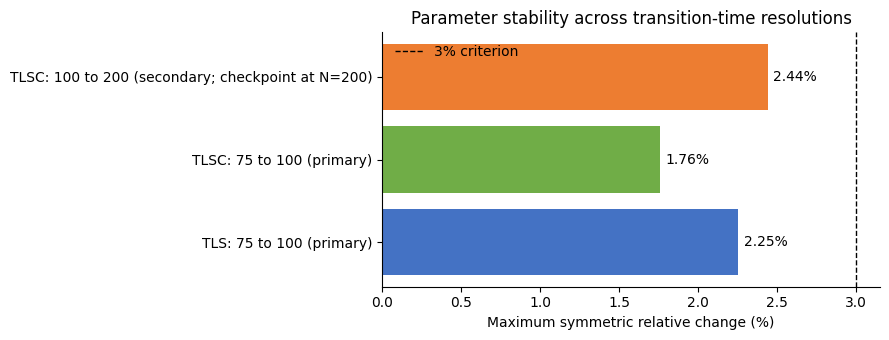

In [4]:
plot_labels = [
    f"{row.condition}: {row.comparison} ({row.comparison_type})"
    for row in summary.itertuples(index=False)
]
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.barh(plot_labels, summary["maximum_symmetric_change_percent"], color=["#4472C4", "#70AD47", "#ED7D31"][:len(summary)])
ax.axvline(RELATIVE_CHANGE_LIMIT_PERCENT, color="black", linestyle="--", linewidth=1, label="3% criterion")
ax.set_xlabel("Maximum symmetric relative change (%)")
ax.set_title("Parameter stability across transition-time resolutions")
ax.legend(frameon=False)
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## Interpretation and limitations

- Use the **primary** 75-to-100 rows to assess the proposed stopping rule. The observed maximum symmetric changes are approximately 2.25% for TLS and 1.76% for TLS$^{\\mathrm{CL}}$; using the lower-resolution estimate as the denominator gives approximately 2.30% and 1.79%, respectively. Both are below 3%.
- The near-zero $a_{\mathrm{NT}}$ estimates for TLS$^{\mathrm{CL}}$ are compared by absolute difference, not relative percentage.
- The TLS$^{\\mathrm{CL}}$ 100-to-200 result is supporting but provisional because the $N=200$ artifact is a checkpoint.
- For TLS, the file named as the $N=200$ run records only 100 transition times, and the audit table shows a traceback in its stderr log. It is excluded from a 100-to-200 convergence comparison; the filename alone is not treated as proof of the actual resolution.
- The TLS $N=75$ and $N=100$ values are also checkpoints. Therefore, the TLS 75-to-100 result is provisional until those fits are finalized. A single adjacent-resolution comparison is a practical stability check, not a mathematical proof of convergence.

For a definitive report, rerun/finalize the TLS fits at $N=75$ and $N=100$, and obtain a valid TLS $N=200$ fit if an additional resolution check is desired. The fitting workflow and plotted quantity $q=p/\Delta t$ are defined in [`Snakefile`](../Snakefile) and [`panel_b.py`](../src/analyses/tls/figure_generator/panel_b.py).